# Detector calibration with likelihood fits

Estimate the response and energy resolution of a detector using a supplied calibration sample. The sample contains 1000 entries at each of seven true energies, $E_0=20,30,\ldots,80$ GeV. The measured energy $E$ is modelled as Gaussian, with

$$\mu(E_0)=\lambda E_0+\Delta,\qquad \sigma^2(E_0)=a^2E_0+b^2+c^2E_0^2.$$

Here $\lambda$ and $c$ are dimensionless; $\Delta$ and $b$ have units GeV, and $a$ has units $\sqrt{\mathrm{GeV}}$. The three estimators below use the same sample, so their results are correlated.

The calibration problem and input sample were provided by Matt Kenzie for *Statistical Methods*. See the README for input-data setup.

In [1]:
from pathlib import Path
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from calibration_tools import analysis, plotting

plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False})
DATA_PATH = Path(os.environ.get('CALIBRATION_DATA_PATH', 'data/sample.csv'))
N_BOOTSTRAP = 2500
SEED = 42

if not DATA_PATH.is_file():
    raise FileNotFoundError('Provide the course sample at data/sample.csv or set CALIBRATION_DATA_PATH.')
df = pd.read_csv(DATA_PATH, usecols=['E_true', 'E_rec'])
E0_arr = df['E_true'].to_numpy(dtype=float)
E_arr = df['E_rec'].to_numpy(dtype=float)
if not np.all(np.isfinite([E0_arr, E_arr])) or np.any(E0_arr <= 0):
    raise ValueError('E_true must be positive and both columns must contain finite numbers.')
E0_vals = np.unique(E0_arr)
counts = df.groupby('E_true').size().rename('Events')
if (counts < 2).any():
    raise ValueError('Each energy group needs at least two measurements.')
display(counts.to_frame())

,Events
E_true,
20,1000
30,1000
40,1000
50,1000
60,1000
70,1000
80,1000


## 1. Sample statistics and weighted least squares

For each energy group, use the sample mean $\bar E$ and standard deviation $s$ with $N-1$ in the variance denominator. Their estimated standard errors are $s/\sqrt{N}$ and $s/\sqrt{2(N-1)}$, respectively; the latter is a large-sample Gaussian approximation. Fit the mean and width models separately using weighted least squares.

Resolution amplitudes have lower bounds $a\geq0.01\sqrt{\mathrm{GeV}}$, $b\geq0.01$ GeV and $c\geq0.001$ throughout the analysis. HESSE supplies the local parameter uncertainty estimates.

In [2]:
sample = analysis.compute_sample_estimates(E_arr, E0_arr, E0_vals)
sample_mean_fit, sample_width_fit = analysis.fit_trends(E0_vals, *sample)
results = {'sample_ests': analysis.summarise_fits(sample_mean_fit, sample_width_fit)}
summary = pd.DataFrame(dict(zip(('Mean [GeV]', 'Mean SE [GeV]', 'Width [GeV]', 'Width SE [GeV]'), sample)),
                       index=pd.Index(E0_vals, name='E0 [GeV]'))
display(summary.round(4))

,Mean [GeV],Mean SE [GeV],Width [GeV],Width SE [GeV]
E0 [GeV],,,,
20.0,22.4455,0.0699,2.2097,0.0494
30.0,32.4789,0.0810,2.5617,0.0573
40.0,42.5537,0.0962,3.0412,0.0680
50.0,52.5394,0.1117,3.5308,0.0790
60.0,62.4278,0.1208,3.8185,0.0854
70.0,73.0681,0.1315,4.1582,0.0930
80.0,82.8500,0.1464,4.6283,0.1035


## 2. Individual Gaussian likelihood fits

At each true energy, fit the unbinned residual distribution $E-E_0$ to a Gaussian. Use the fitted means, widths and their HESSE errors in the same two weighted trend fits. The pooled residual density is the sum of the fitted Gaussian densities, weighted by each group's event fraction.

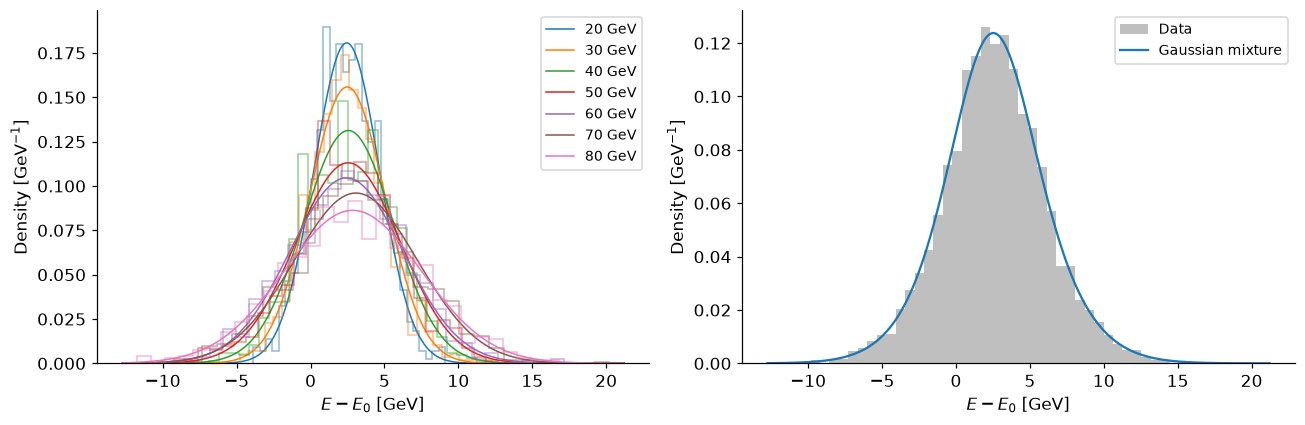

In [3]:
individual = analysis.compute_mle_estimates(E_arr, E0_arr, E0_vals)
individual_mean_fit, individual_width_fit = analysis.fit_trends(E0_vals, *individual[:4])
results['individual_fits'] = analysis.summarise_fits(individual_mean_fit, individual_width_fit)
fig = plotting.plot_distributions(E_arr, E0_arr, E0_vals, individual[0], individual[2])
plt.show()

## 3. Simultaneous likelihood fit

Fit all five parameters directly from the event-level likelihood,

$$L(\lambda,\Delta,a,b,c)=\prod_i\frac{1}{\sqrt{2\pi}\sigma(E_{0,i})}
\exp\left[-\frac{(E_i-\mu(E_{0,i}))^2}{2\sigma^2(E_{0,i})}\right].$$

The plotted bands propagate the fitted covariance through the calibration model using 1000 multivariate-normal parameter draws. They describe a local Gaussian approximation to parameter uncertainty, rather than resampling the observations.

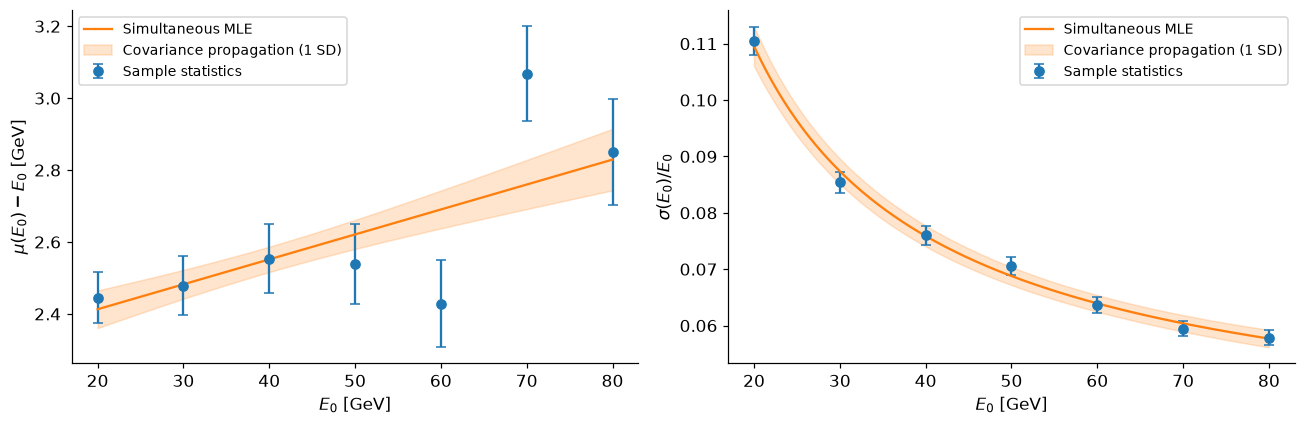

In [4]:
simultaneous_fit = analysis.compute_simultaneous_fit(E_arr, E0_arr)
results['simultaneous_fit'] = analysis.summarise_fits(simultaneous_fit)
fig = plotting.plot_calibration(E0_vals, sample, simultaneous_fit)
plotting.save_figure(fig, 'calibration')
plt.show()

,,Estimate,HESSE SE
Parameter,Method,,
lamb,sample_ests,1.007014,0.001964
delt,sample_ests,2.271953,0.087342
a,sample_ests,0.371109,0.062327
b,sample_ests,1.226697,0.345640
c,sample_ests,0.036916,0.007184
lamb,individual_fits,1.007014,0.001962
delt,individual_fits,2.271953,0.087275
a,individual_fits,0.370894,0.062905
b,individual_fits,1.226212,0.348593


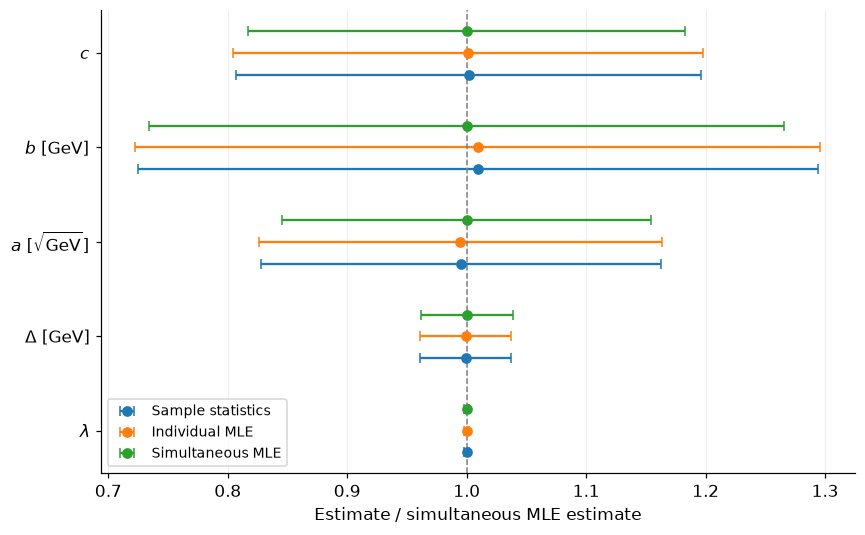

In [5]:
rows = []
for method in analysis.METHODS:
    for parameter in analysis.PARAMETERS:
        rows.append({'Method': method, 'Parameter': parameter,
                     'Estimate': results[method]['values'][parameter],
                     'HESSE SE': results[method]['errors'][parameter]})
fit_table = pd.DataFrame(rows).set_index(['Parameter', 'Method'])
display(fit_table.round(6))
Path('results.json').write_text(json.dumps(results, indent=2, allow_nan=False) + '\n')
fig = plotting.plot_estimates(results)
plt.show()

## 4. Whole-sample bootstrap

Sample the paired $(E_0,E)$ rows with replacement and repeat all three analyses for 2500 replicates. The number of entries in each energy group can vary between replicates; the sample standard errors use the actual group sizes. The bootstrap is seeded independently of the draws used for the calibration plot.

The histograms show the parameter distributions. Dashed lines indicate the point estimates fitted to the calibration sample.

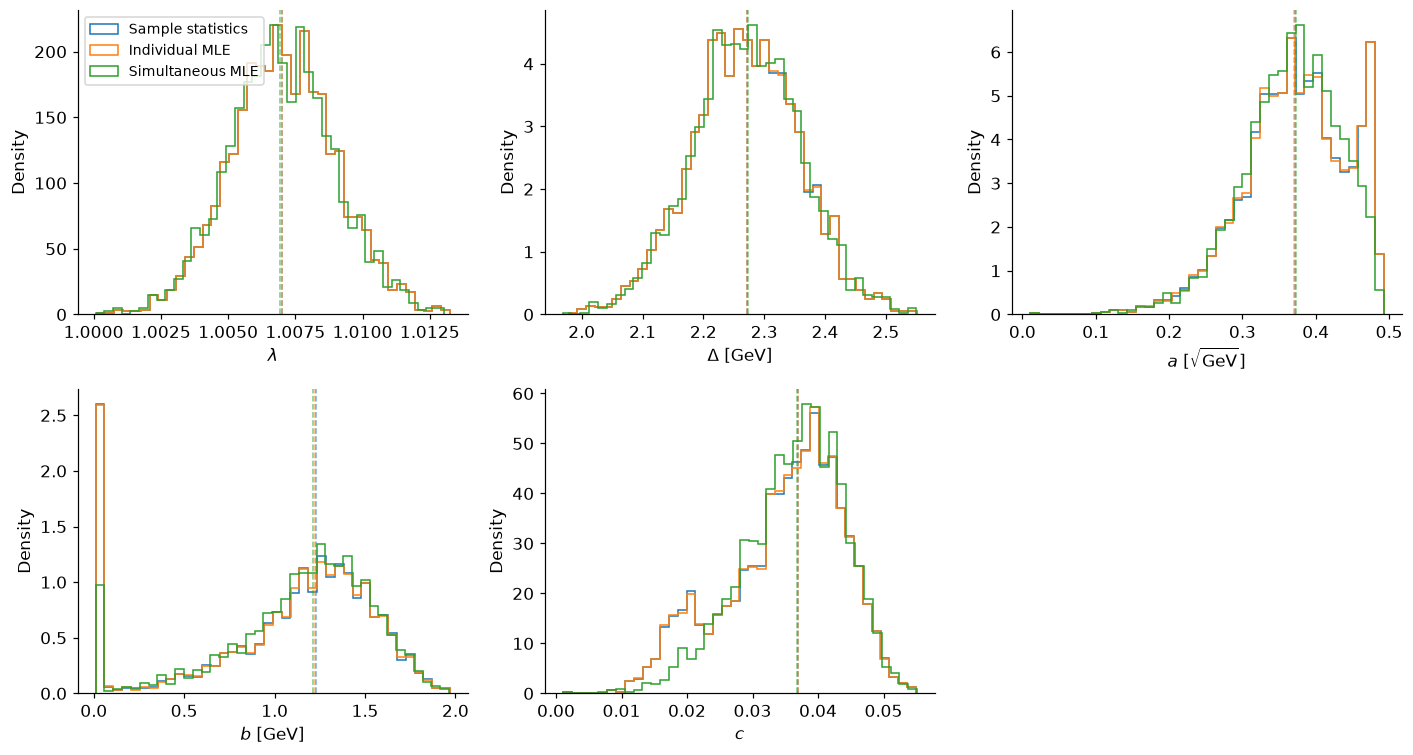

In [6]:
bootstrap_arrays = analysis.bootstrap_analysis(
    E_arr, E0_arr, E0_vals, n_bootstrap=N_BOOTSTRAP, seed=SEED,
)
bootstrap_results = {
    method: {
        'values': dict(zip(analysis.PARAMETERS, values.mean(axis=0).tolist())),
        'errors': dict(zip(analysis.PARAMETERS, values.std(axis=0, ddof=1).tolist())),
    }
    for method, values in bootstrap_arrays.items()
}
Path('bootstrap_summary.json').write_text(json.dumps(
    {'replicates': N_BOOTSTRAP, 'seed': SEED, 'methods': bootstrap_results},
    indent=2, allow_nan=False,
) + '\n')
fig = plotting.plot_bootstrap(bootstrap_arrays, results)
plotting.save_figure(fig, 'bootstrap')
plt.show()

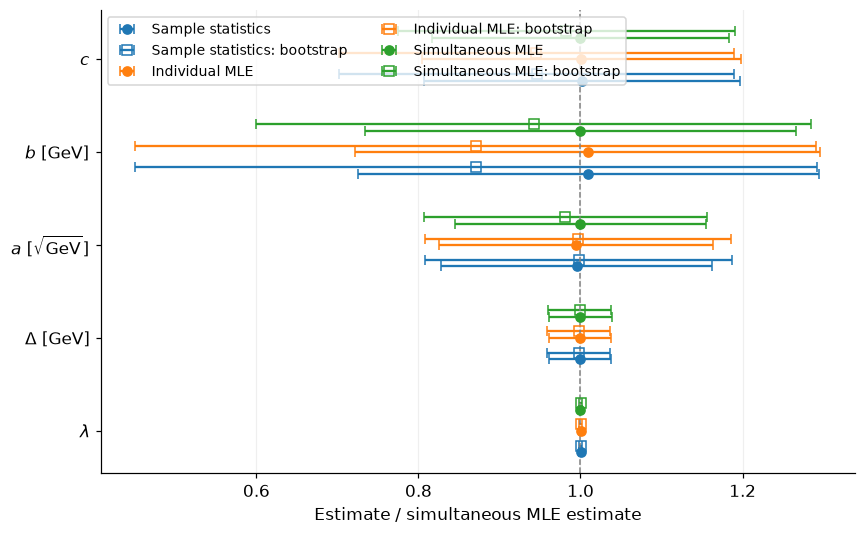

,,Bootstrap SD / HESSE SE,Bootstrap mean - point estimate
Parameter,Method,,
lamb,sample_ests,0.99426,0.00004
delt,sample_ests,1.01074,-0.00292
a,sample_ests,1.13175,0.00098
b,sample_ests,1.47897,-0.16858
c,sample_ests,1.25102,-0.00206
lamb,individual_fits,0.99497,0.00004
delt,individual_fits,1.01152,-0.00292
a,individual_fits,1.11949,0.00100
b,individual_fits,1.46544,-0.16844


In [7]:
fig = plotting.plot_estimates(results, bootstrap_results)
plt.show()

rows = []
for method in analysis.METHODS:
    for j, parameter in enumerate(analysis.PARAMETERS):
        values = bootstrap_arrays[method][:, j]
        point = results[method]['values'][parameter]
        hesse_se = results[method]['errors'][parameter]
        rows.append({'Method': method, 'Parameter': parameter,
                     'Bootstrap SD / HESSE SE': values.std(ddof=1) / hesse_se,
                     'Bootstrap mean - point estimate': values.mean() - point})
display(pd.DataFrame(rows).set_index(['Parameter', 'Method']).round(5))

## Interpretation

The three estimates can be compared directly in the parameter table and relative-error plot. For a Gaussian response, the sample and individual maximum-likelihood estimators of the mean agree; their width estimates differ slightly because they use different variance denominators. The joint likelihood fits the calibration model directly instead of first reducing each group to separate estimates.

The bootstrap standard deviations measure variation across resampled datasets. Their ratio to the HESSE errors is a comparison of uncertainty scales, not a measurement of confidence-interval coverage. Likewise, the difference between the bootstrap mean and point estimate is a bootstrap bias diagnostic; it does not establish the true bias of an estimator.

The resolution parameters are correlated. In particular, the $b^2/E_0^2$ contribution to relative variance becomes small at higher energy. Boundary accumulation and asymmetric bootstrap distributions can therefore make symmetric local errors less informative for $b$. These conclusions are conditional on the Gaussian detector-response model and the stated parameter bounds.